In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones normal y tope (semanas) y coste unitario de reducción CUR (k€/semana) se adjunta. Las actividades con CUR infinito no pueden acelerarse. Se quiere reducir la duración del proyecto en 3 semanas con el mínimo sobrecoste.

In [4]:
pregunta_1 = "1. Calcule la duración normal del proyecto, construya la matriz de caminos $R$ y la duración de cada ruta.  "
pregunta_2 = "2. Aplique el algoritmo de Ackoff-Sasieni para reducir 3 semanas y obtenga el sobrecoste total.  "
pregunta_3 = "3. Plantee el problema como un programa lineal: variables $x_i$ = semanas que se acorta la actividad $i$; minimizar $\\sum_i CUR_i\\, x_i$ sujeto a que ninguna ruta supere la duración objetivo, $R\\,(d - x) \\le T_{obj}$, y $0 \\le x_i \\le d_i - d_i^{tope}$. Resuélvalo con `scipy.optimize.linprog`.  "
pregunta_4 = "4. Compare las dos soluciones. ¿Puede el algoritmo voraz ser peor que el óptimo? ¿Por qué el programa lineal da aquí soluciones enteras?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule la duración normal del proyecto, construya la matriz de caminos $R$ y la duración de cada ruta.  

2. Aplique el algoritmo de Ackoff-Sasieni para reducir 3 semanas y obtenga el sobrecoste total.  

3. Plantee el problema como un programa lineal: variables $x_i$ = semanas que se acorta la actividad $i$; minimizar $\sum_i CUR_i\, x_i$ sujeto a que ninguna ruta supere la duración objetivo, $R\,(d - x) \le T_{obj}$, y $0 \le x_i \le d_i - d_i^{tope}$. Resuélvalo con `scipy.optimize.linprog`.  

4. Compare las dos soluciones. ¿Puede el algoritmo voraz ser peor que el óptimo? ¿Por qué el programa lineal da aquí soluciones enteras?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, ucr   
    ('A'     , '---'      , 3       , 1           , 5     ),
    ('B'     , '---'      , 2       , 2           , np.inf),
    ('C'     , 'A,B'      , 7       , 6           , 4     ),
    ('D'     , 'C'        , 7       , 7           , np.inf),
    ('E'     , 'B'        , 4       , 3           , 1     ),
    ('F'     , 'C,E'      , 8       , 8           , np.inf),
    ('G'     , 'D,E'      , 5       , 3           , 9     ),
    ('H'     , 'F,G'      , 4       , 1           , 1     ),
    ('I'     , 'H'        , 5       , 5           , np.inf),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'ucr']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,ucr
activity,,,,
A,---,3,1,5.0
B,---,2,2,inf
C,"A,B",7,6,4.0
D,C,7,7,inf
E,B,4,3,1.0
F,"C,E",8,8,inf
G,"D,E",5,3,9.0
H,"F,G",4,1,1.0
I,H,5,5,inf


El proyecto corresponde a la organización de un congreso científico; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Definición del programa y fechas',
    'B': 'Reserva de la sede',
    'C': 'Convocatoria de comunicaciones',
    'D': 'Página web e inscripciones',
    'E': 'Contratación de ponentes invitados',
    'F': 'Revisión de los trabajos recibidos',
    'G': 'Elaboración del programa definitivo',
    'H': 'Contratación de catering y viajes',
    'I': 'Edición del libro de actas',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Definición del programa y fechas
B,Reserva de la sede
C,Convocatoria de comunicaciones
D,Página web e inscripciones
E,Contratación de ponentes invitados
F,Revisión de los trabajos recibidos
G,Elaboración del programa definitivo
H,Contratación de catering y viajes
I,Edición del libro de actas


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
reduccion = 3

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Calcule la duración normal del proyecto, construya la matriz de caminos $R$ y la duración de cada ruta.  

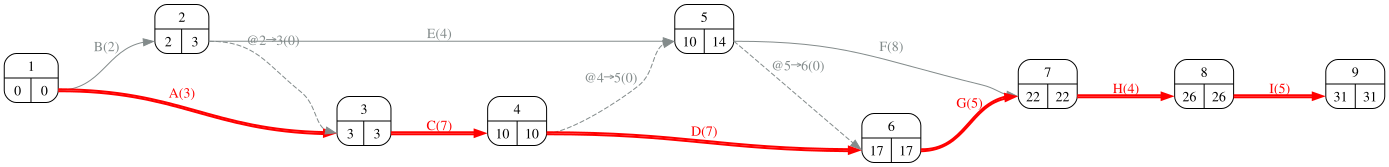

In [9]:
#| fig-cap: "Grafo PERT con las duraciones normales"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [10]:
#| tbl-cap: "Matriz de caminos y duración de cada ruta"
#| label: tbl-rutas
R = proyecto.path_matrix(dummies=False)
duracion_normal = proyecto.duration(datos_proyecto['duration'])
T_objetivo = duracion_normal - reduccion
detalle_rutas(R, datos_proyecto['duration'][R.columns])

,actividades,duración = suma,duración
Route_1,A - C - D - G - H - I,A(3) + C(7) + D(7) + G(5) + H(4) + I(5) = 31,31.0
Route_2,A - C - F - H - I,A(3) + C(7) + F(8) + H(4) + I(5) = 27,27.0
Route_3,A - C - G - H - I,A(3) + C(7) + G(5) + H(4) + I(5) = 24,24.0
Route_4,B - C - D - G - H - I,B(2) + C(7) + D(7) + G(5) + H(4) + I(5) = 30,30.0
Route_5,B - C - F - H - I,B(2) + C(7) + F(8) + H(4) + I(5) = 26,26.0
Route_6,B - C - G - H - I,B(2) + C(7) + G(5) + H(4) + I(5) = 23,23.0
Route_7,B - E - F - H - I,B(2) + E(4) + F(8) + H(4) + I(5) = 23,23.0
Route_8,B - E - G - H - I,B(2) + E(4) + G(5) + H(4) + I(5) = 20,20.0


## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Aplique el algoritmo de Ackoff-Sasieni para reducir 3 semanas y obtenga el sobrecoste total.  

In [12]:
#| tbl-cap: "Algoritmo de Ackoff-Sasieni"
#| label: tbl-ackoff
tabla_ackoff, pasos, duraciones_ackoff, margen_restante = proyecto.ackoff(
    durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'], reduction=reduccion, report=False)
tabla_ackoff

,A,B,C,D,E,F,G,H,I,0,1,2,3
Route_1,5.0,,4.0,inf,,,9.0,1.0,inf,31.0,30.0,29.0,28.0
Route_2,5.0,,4.0,,,inf,,1.0,inf,27.0,26.0,25.0,24.0
Route_3,5.0,,4.0,,,,9.0,1.0,inf,24.0,23.0,22.0,21.0
Route_4,,inf,4.0,inf,,,9.0,1.0,inf,30.0,29.0,28.0,27.0
Route_5,,inf,4.0,,,inf,,1.0,inf,26.0,25.0,24.0,23.0
Route_6,,inf,4.0,,,,9.0,1.0,inf,23.0,22.0,21.0,20.0
Route_7,,inf,,,1.0,inf,,1.0,inf,23.0,22.0,21.0,20.0
Route_8,,inf,,,1.0,,9.0,1.0,inf,20.0,19.0,18.0,17.0
0,2.0,0.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,,,,
1,2.0,0.0,1.0,0.0,1.0,0.0,2.0,2.0,0.0,,,,


In [13]:
#| tbl-cap: "Opciones consideradas en cada paso"
#| label: tbl-ackoffPaso
detalle_ackoff(proyecto, datos_proyecto['duration'], datos_proyecto['cap_duration'], datos_proyecto['ucr'], pasos)

,duración,rutas críticas,opciones (coste),elegida,coste del paso
paso,,,,,
1,31,Route_1,H (1); C (4); A (5); G (9),H,1.0
2,30,Route_1,H (1); C (4); A (5); G (9),H,1.0
3,29,Route_1,H (1); C (4); A (5); G (9),H,1.0


In [14]:
x_ackoff = (datos_proyecto['duration'] - duraciones_ackoff.reindex(datos_proyecto.index)).astype(int)
coste_ackoff = float((x_ackoff * datos_proyecto['ucr'].replace(np.inf, 0)).sum())
Markdown(f'Ackoff-Sasieni acorta {", ".join(f"{a} ({int(x)})" for a, x in x_ackoff[x_ackoff > 0].items())} con un sobrecoste de {coste_ackoff:.0f} k€; duración {proyecto.duration(duraciones_ackoff)}.')

Ackoff-Sasieni acorta H (3) con un sobrecoste de 3 k€; duración 28.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. Plantee el problema como un programa lineal: variables $x_i$ = semanas que se acorta la actividad $i$; minimizar $\sum_i CUR_i\, x_i$ sujeto a que ninguna ruta supere la duración objetivo, $R\,(d - x) \le T_{obj}$, y $0 \le x_i \le d_i - d_i^{tope}$. Resuélvalo con `scipy.optimize.linprog`.  

Cada fila de $R$ es una ruta; $R\,d$ son las duraciones de las rutas y $R\,x$ lo que se acorta cada una. La restricción $R\,(d - x) \le T_{obj}$ se escribe como $-R\,x \le T_{obj} - R\,d$ para `linprog` (que exige la forma $A x \le b$).

In [16]:
from scipy.optimize import linprog
acts = list(R.columns)
d = datos_proyecto.loc[acts, 'duration'].astype(float).values
cur = datos_proyecto.loc[acts, 'ucr'].astype(float)
margen = (datos_proyecto.loc[acts, 'duration'] - datos_proyecto.loc[acts, 'cap_duration']).astype(float)
c = cur.replace(np.inf, 0).values                       # coste por semana acortada
cotas = [(0, 0 if np.isinf(cur[a]) else margen[a]) for a in acts]
A_ub = -R.values.astype(float)
b_ub = T_objetivo - R.values @ d
solucion = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=cotas, method='highs')
x_lp = pd.Series(solucion.x, index=acts).round(6)
coste_lp = float(solucion.fun)
entera = bool(np.allclose(x_lp, x_lp.round()))
pd.DataFrame({'x (Ackoff)': x_ackoff.reindex(acts), 'x (PL)': x_lp, 'CUR': cur}).T

,A,B,C,D,E,F,G,H,I
x (Ackoff),0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0
x (PL),0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0
CUR,5.0,inf,4.0,inf,1.0,inf,9.0,1.0,inf


In [17]:
duraciones_lp = datos_proyecto['duration'] - x_lp.reindex(datos_proyecto.index).fillna(0)
Markdown(f'La programación lineal acorta {", ".join(f"{a} ({x:g})" for a, x in x_lp[x_lp > 0].items())} con sobrecoste {coste_lp:.0f} k€; '
         f'todas las rutas quedan en como mucho {float((R @ duraciones_lp[acts]).max()):g} semanas (objetivo {T_objetivo}).')

La programación lineal acorta H (3) con sobrecoste 3 k€; todas las rutas quedan en como mucho 28 semanas (objetivo 28).

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. Compare las dos soluciones. ¿Puede el algoritmo voraz ser peor que el óptimo? ¿Por qué el programa lineal da aquí soluciones enteras?  

In [19]:
Markdown(f'''Aquí las dos soluciones cuestan lo mismo: el algoritmo voraz ha acertado. No siempre es así: decide semana a semana y no revisa decisiones anteriores, por lo que puede ser más caro que el óptimo cuando una actividad acortada pronto deja de ser útil al cambiar las rutas críticas. {'Aquí el PL ha dado una solución entera' if entera else 'Aquí el PL ha dado una solución fraccionaria'}: con datos enteros suele ocurrir, pero no está garantizado (la matriz de caminos no es en general totalmente unimodular); si hiciera falta, habría que exigir x entera con un programa entero, que `linprog` no resuelve. En todo caso el óptimo del PL es una cota inferior del coste de cualquier reducción entera.''')

Aquí las dos soluciones cuestan lo mismo: el algoritmo voraz ha acertado. No siempre es así: decide semana a semana y no revisa decisiones anteriores, por lo que puede ser más caro que el óptimo cuando una actividad acortada pronto deja de ser útil al cambiar las rutas críticas. Aquí el PL ha dado una solución entera: con datos enteros suele ocurrir, pero no está garantizado (la matriz de caminos no es en general totalmente unimodular); si hiciera falta, habría que exigir x entera con un programa entero, que `linprog` no resuelve. En todo caso el óptimo del PL es una cota inferior del coste de cualquier reducción entera.